# победитель матча dota 2

базовая модель: изучение данных, очистка составов, признаки и логистическая регрессия.

лучший gini исходного запуска на ноябре — 0,31101. ниже результаты локального повторного запуска.

In [1]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import sys
project_root = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src' / 'dota_project').is_dir()))
sys.path.insert(0, str(project_root / 'src'))
from dota_project.paths import data_path, output_path
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)


## метрика

модели сравниваются по gini = 2 × roc-auc − 1. классы близки по размеру, поэтому такая метрика подходит для оценки ранжирования.

In [2]:
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1.0


## данные

предсказывается победа radiant по информации, доступной до конца 15-й минуты. duration известна после матча, поэтому в модель не добавляется.

In [3]:
import pandas as pd
data_dir = data_path(project_root)
OUTPUT = output_path(project_root, 'baseline')
train_path = data_dir / 'matches_df_train.csv'
test_path = data_dir / 'matches_df_test.csv'
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
print(train.shape, test.shape)


(641090, 7) (59748, 5)


duration известна после завершения матча, поэтому исключается из признаков.

In [4]:
display(train.head())
display(test.head())
column_meanings = {'match_id': 'идентификатор матча', 'date': 'дата матча', 'region': 'регион сервера', 'game_mode': 'код игрового режима', 'avg_mmr': 'средний рейтинг участников', 'duration': 'итоговая длительность в секундах, только train', 'radiant_win': 'таргет: победила ли radiant, только train'}
display(pd.Series(column_meanings, name='содержание колонки'))


,match_id,date,region,game_mode,duration,radiant_win,avg_mmr
0,1,2024-02-12,Europe West,4,2625,False,3519.7
1,2,2024-04-08,South Africa,2,7526,True,2330.9
2,3,2024-06-16,SE Asia,1,2831,True,1579.6
3,4,2024-09-16,Middle East,22,1438,False,NaN
4,5,2024-03-31,South Africa,22,2051,True,NaN


,match_id,date,region,game_mode,avg_mmr
0,8,2024-12-01,China,1,2305.0
1,29,2024-12-17,Europe West,22,NaN
2,34,2024-12-19,Europe West,22,2278.5
3,36,2024-12-19,Europe West,1,305.8
4,61,2024-12-06,Australia,1,5142.4


match_id                                  идентификатор матча
date                                               дата матча
region                                         регион сервера
game_mode                                 код игрового режима
avg_mmr                            средний рейтинг участников
duration       итоговая длительность в секундах, только train
radiant_win         таргет: победила ли radiant, только train
Name: содержание колонки, dtype: str

In [5]:
print(f'train size - {train_path.stat().st_size / 1000000:.2f} mb')
print(f'test size - {test_path.stat().st_size / 1000000:.2f} mb')


train size - 30.37 mb
test size - 2.18 mb


### баланс классов

доли классов близки: примерно 51% и 49%.

,матчей,"доля, %"
radiant_win,,
False,313639,48.922772
True,327451,51.077228


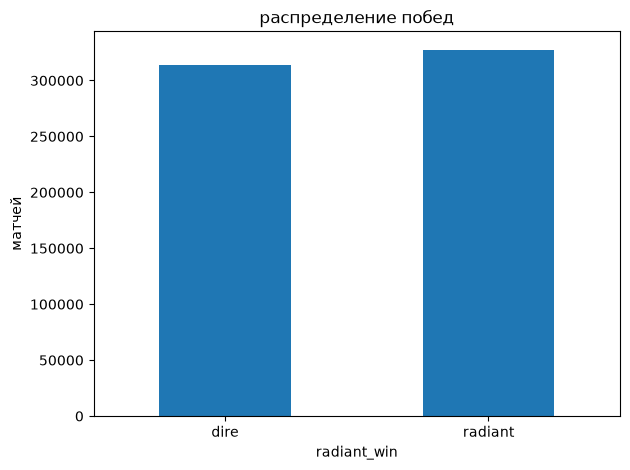

In [6]:
import matplotlib.pyplot as plt
target_counts = train['radiant_win'].value_counts().sort_index()
display(pd.DataFrame({'матчей': target_counts, 'доля, %': target_counts / len(train) * 100}))
ax = target_counts.rename(index={False: 'dire', True: 'radiant'}).plot.bar(rot=0, ylabel='матчей', title='распределение побед')
plt.tight_layout()
plt.show()


## регионы

регионы отличаются и по числу матчей, и по доле побед. для редких регионов оценки менее надёжны.

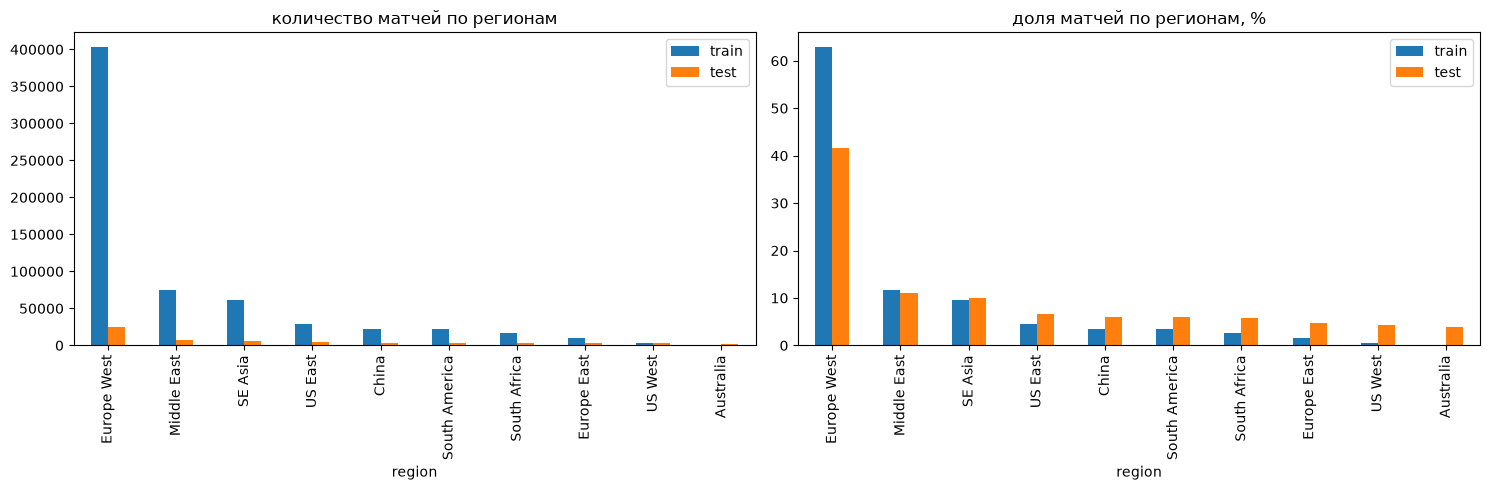

,mean,size
region,,
US West,0.364363,3255
US East,0.413281,28281
Middle East,0.436854,74542
South America,0.483214,21864
South Africa,0.490883,16782
SE Asia,0.501893,61555
China,0.510876,21929
Australia,0.533546,626
Europe West,0.534574,402930


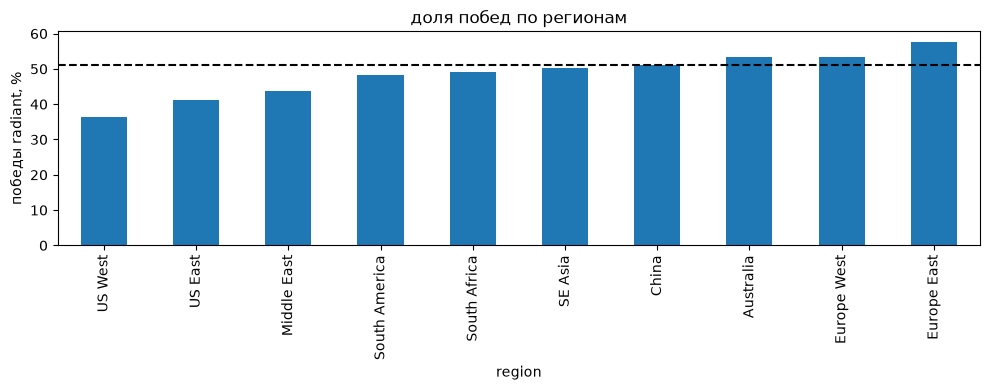

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
region_counts = pd.concat([train['region'].value_counts().rename('train'), test['region'].value_counts().rename('test')], axis=1).fillna(0)
region_shares = region_counts.div(region_counts.sum(), axis=1) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
region_counts.plot.bar(ax=axes[0], title='количество матчей по регионам')
region_shares.plot.bar(ax=axes[1], title='доля матчей по регионам, %')
plt.tight_layout()
plt.show()
region_target = train.groupby('region')['radiant_win'].agg(['mean', 'size']).sort_values('mean')
display(region_target)
(region_target['mean'] * 100).plot.bar(figsize=(10, 4), ylabel='победы radiant, %', title='доля побед по регионам')
plt.axhline(train['radiant_win'].mean() * 100, color='black', linestyle='--')
plt.tight_layout()
plt.show()


### кодирование регионов

используется one-hot: категорий немного, а порядок между ними не нужен. новые значения не должны ломать прогноз.

In [8]:
region_encoder = OneHotEncoder(handle_unknown='ignore')
region_train = region_encoder.fit_transform(train[['region']])
region_test = region_encoder.transform(test[['region']])
print(region_train.shape, region_test.shape)
print(region_encoder.get_feature_names_out())


(641090, 10) (59748, 10)
['region_Australia' 'region_China' 'region_Europe East'
 'region_Europe West' 'region_Middle East' 'region_SE Asia'
 'region_South Africa' 'region_South America' 'region_US East'
 'region_US West']


## время

доля побед меняется по месяцам. возможная причина — изменения баланса игры, но по одному графику это не доказать.

train 2024-01-01 00:00:00 2024-11-30 00:00:00
test 2024-12-01 00:00:00 2024-12-31 00:00:00


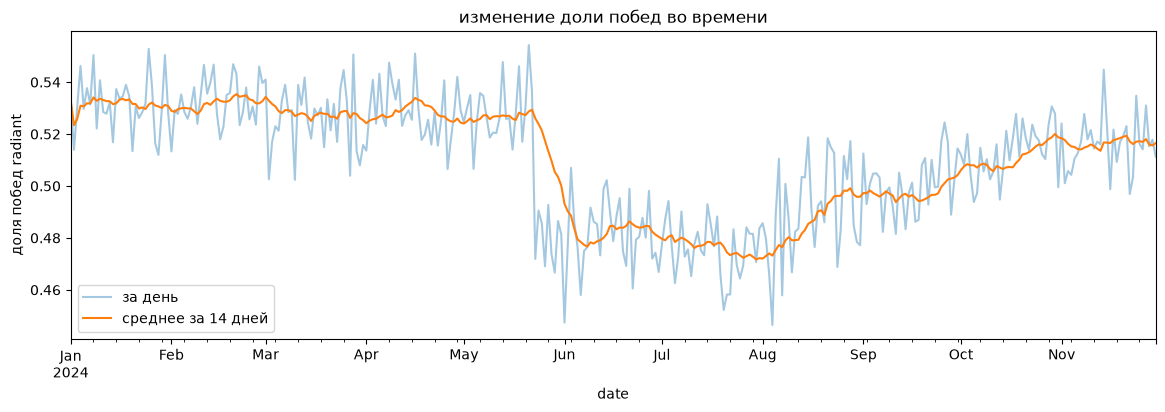

,mean,size
date,,
2024-01,0.531584,61629
2024-02,0.532439,57877
2024-03,0.525938,61281
2024-04,0.528689,59534
2024-05,0.515408,59968
2024-06,0.481350,53672
2024-07,0.475781,55618
2024-08,0.490274,57064
2024-09,0.500517,56102


In [9]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
for name, df in [('train', train), ('test', test)]:
    print(name, df['date'].min(), df['date'].max())
daily = train.groupby('date')['radiant_win'].agg(['mean', 'size'])
ax = daily['mean'].plot(figsize=(14, 4), alpha=0.4, label='за день')
daily['mean'].rolling(14, min_periods=1).mean().plot(ax=ax, label='среднее за 14 дней')
ax.set(ylabel='доля побед radiant', title='изменение доли побед во времени')
plt.legend()
plt.show()
display(train.groupby(train['date'].dt.to_period('M'))['radiant_win'].agg(['mean', 'size']))


### признаки даты

день, день недели и месяц кодируются через sin и cos, чтобы сохранить цикличность.

In [10]:
date_columns = ['day_sin', 'day_cos', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'weekend']
for df in [train, test]:
    date = df['date']
    df['day_sin'] = np.sin(2 * np.pi * (date.dt.day - 1) / date.dt.days_in_month)
    df['day_cos'] = np.cos(2 * np.pi * (date.dt.day - 1) / date.dt.days_in_month)
    df['weekday_sin'] = np.sin(2 * np.pi * date.dt.dayofweek / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * date.dt.dayofweek / 7)
    df['month_sin'] = np.sin(2 * np.pi * (date.dt.month - 1) / 12)
    df['month_cos'] = np.cos(2 * np.pi * (date.dt.month - 1) / 12)
    df['weekend'] = (date.dt.dayofweek >= 5).astype(int)
display(train[['date'] + date_columns].head())


,date,day_sin,day_cos,weekday_sin,weekday_cos,month_sin,month_cos,weekend
0,2024-02-12,6.876995e-01,-0.725995,0.000000,1.00000,0.500000,8.660254e-01,0
1,2024-04-08,9.945219e-01,0.104528,0.000000,1.00000,1.000000,6.123234e-17,0
2,2024-06-16,5.665539e-16,-1.000000,-0.781831,0.62349,0.500000,-8.660254e-01,1
3,2024-09-16,5.665539e-16,-1.000000,0.000000,1.00000,-0.866025,-5.000000e-01,0
4,2024-03-31,-2.012985e-01,0.979530,-0.781831,0.62349,0.866025,5.000000e-01,1


## валидация

обучение — январь–октябрь 2024, валидация — ноябрь, test — декабрь. так проверка ближе к прогнозу будущих матчей.

In [11]:
cutoff = train['date'].max().to_period('M').start_time
fit_df = train.loc[train['date'] < cutoff].copy()
valid_df = train.loc[train['date'] >= cutoff].copy()
assert fit_df['date'].max() < valid_df['date'].min()
print('граница oot:', cutoff)
print('train:', fit_df.shape, 'valid:', valid_df.shape)


граница oot: 2024-11-01 00:00:00
train: (582297, 14) valid: (58793, 14)


### первые модели

сравниваются даты, регионы и их сочетание. даты дают небольшой прирост на выбранном месяце.

In [12]:
results = []
models = {}

def make_model(use_dates=False, mmr=None, params=None):
    blocks = [('region', OneHotEncoder(handle_unknown='ignore'), ['region'])]
    if use_dates:
        blocks.append(('dates', StandardScaler(), date_columns))
    if mmr is not None:
        transform = np.log1p if mmr == 'log' else None
        steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
        if transform is not None:
            steps = [('log', FunctionTransformer(np.log1p)), ('impute', SimpleImputer(strategy='median', add_indicator=True))]
        steps.append(('scale', StandardScaler()))
        blocks.append(('mmr', Pipeline(steps), ['avg_mmr']))
    settings = dict(C=1.0, solver='lbfgs', max_iter=500, random_state=42)
    settings.update(params or {})
    return Pipeline([('features', ColumnTransformer(blocks)), ('model', LogisticRegression(**settings))])

def evaluate_model(name, model, train_data, valid_data):
    model.fit(train_data, train_data['radiant_win'])
    row = {'model': name, 'gini_train': gini(train_data['radiant_win'], model.predict_proba(train_data)[:, 1]), 'gini_valid': gini(valid_data['radiant_win'], model.predict_proba(valid_data)[:, 1])}
    results.append(row)
    models[name] = model
    return row
dates_model = Pipeline([('features', ColumnTransformer([('dates', StandardScaler(), date_columns)])), ('model', LogisticRegression(max_iter=500))])
evaluate_model('dates', dates_model, fit_df, valid_df)
evaluate_model('region', make_model(), fit_df, valid_df)
evaluate_model('dates_region', make_model(use_dates=True), fit_df, valid_df)
display(pd.DataFrame(results))
use_dates = results[-1]['gini_valid'] > results[-2]['gini_valid']
print('даты в модели:', use_dates)


,model,gini_train,gini_valid
0,dates,0.044577,0.004557
1,region,0.075595,0.075964
2,dates_region,0.096057,0.077887


даты в модели: True


## рейтинг игроков

у mmr есть правый хвост и пропуски. исходные значения сравниваются с log1p. медиана и масштаб считаются только на обучении.

train доля пропусков 0.26132540610719274
valid доля пропусков 0.2821254230945861
test доля пропусков 0.2551382473053491


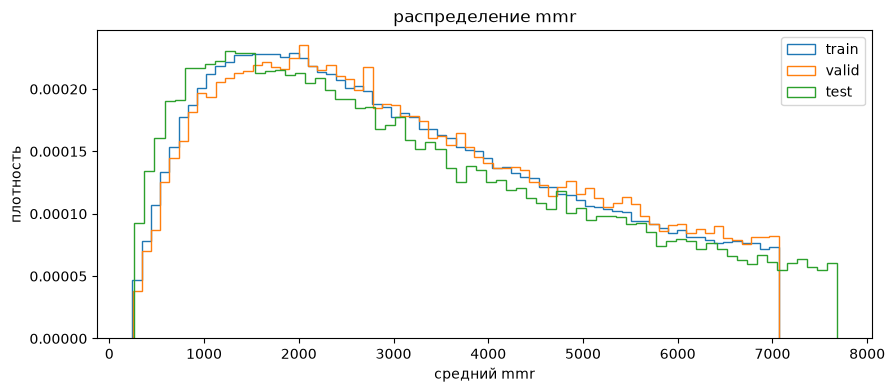

,train,valid,test
count,430128.000000,42206.000000,44504.000000
mean,3127.333402,3201.139928,3155.675807
std,1758.777705,1763.983029,1926.963244
min,243.700000,245.100000,265.000000
25%,1670.300000,1745.325000,1551.675000
50%,2839.900000,2920.600000,2778.750000
75%,4420.300000,4525.375000,4535.650000
max,7065.400000,7065.300000,7680.600000


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, df in [('train', fit_df), ('valid', valid_df), ('test', test)]:
    df['avg_mmr'].dropna().plot.hist(bins=70, density=True, histtype='step', ax=ax, label=name)
    print(name, 'доля пропусков', df['avg_mmr'].isna().mean())
ax.set(xlabel='средний mmr', ylabel='плотность', title='распределение mmr')
plt.legend()
plt.show()
display(pd.DataFrame({name: df['avg_mmr'].describe() for name, df in [('train', fit_df), ('valid', valid_df), ('test', test)]}))


для сравнения выбран log1p: он сжимает правый хвост. exp(log(x)) при x > 0 возвращает исходное x.

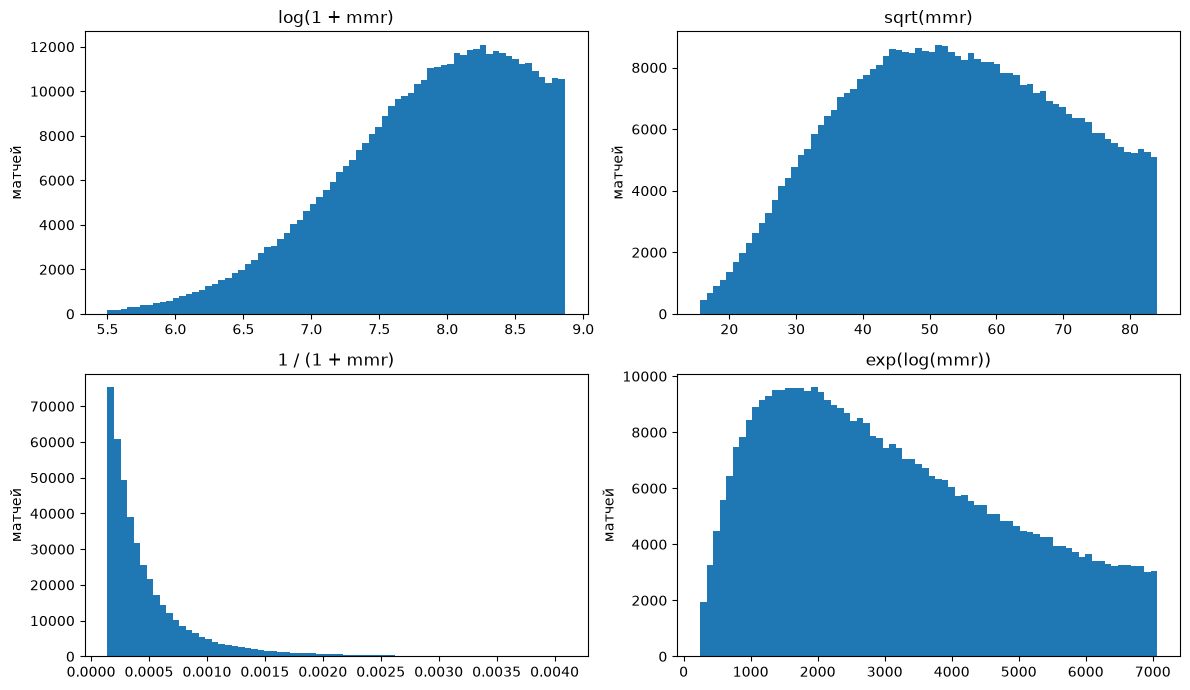

In [14]:
mmr_values = fit_df['avg_mmr'].dropna()
transforms = {'log(1 + mmr)': np.log1p(mmr_values), 'sqrt(mmr)': np.sqrt(mmr_values), '1 / (1 + mmr)': 1 / (1 + mmr_values), 'exp(log(mmr))': np.exp(np.log(mmr_values[mmr_values > 0]))}
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, values) in zip(axes.flat, transforms.items()):
    ax.hist(values, bins=70)
    ax.set(title=name, ylabel='матчей')
plt.tight_layout()
plt.show()


In [15]:
evaluate_model('mmr_raw', make_model(use_dates=use_dates, mmr='raw'), fit_df, valid_df)
evaluate_model('mmr_log', make_model(use_dates=use_dates, mmr='log'), fit_df, valid_df)
display(pd.DataFrame(results))
mmr_kind = 'log' if results[-1]['gini_valid'] > results[-2]['gini_valid'] else 'raw'
print('выбрано преобразование mmr:', mmr_kind)


,model,gini_train,gini_valid
0,dates,0.044577,0.004557
1,region,0.075595,0.075964
2,dates_region,0.096057,0.077887
3,mmr_raw,0.152860,0.145717
4,mmr_log,0.154762,0.146929


выбрано преобразование mmr: log


## составы команд

анонимные аккаунты сохраняются: их слишком много, чтобы удалять. отрицательные технические id и повреждённые составы исключаются из train.

ниже сравниваются доли пропусков в статистике игроков для train и test.

In [16]:
data_dir = train_path.parent
player_raw = pd.read_csv(data_dir / 'player_df.csv')
heroes = pd.read_csv(data_dir / 'Constants.Heroes.csv')
display(player_raw.head())
display(player_raw['account_id'].value_counts().head(15))
suspicious_ids = [-1, 4294967295]
for account in suspicious_ids:
    affected = player_raw.loc[player_raw['account_id'].eq(account), 'match_id'].nunique()
    print(account, 'матчей:', affected, 'доля:', affected / player_raw['match_id'].nunique())
display(pd.DataFrame({name: player_raw.loc[player_raw['match_id'].isin(df['match_id'])].isna().mean() for name, df in [('train', train), ('test', test)]}))
player_df = player_raw[['match_id', 'player_slot', 'account_id', 'hero_id']].copy()
del player_raw


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id
0,130,10111871,5,3.0,8.0,15.0,2971.0,55.0,3.0,291.0,390.0,7431.0,146.0,215380
1,130,43341844,3,3.0,9.0,3.0,1245.0,25.0,3.0,238.0,346.0,4187.0,34.0,185234
2,130,72157343,53,9.0,6.0,20.0,4544.0,226.0,1.0,583.0,704.0,9406.0,2375.0,573078
3,1,4294967295,17,21.0,3.0,15.0,2945.0,209.0,12.0,577.0,641.0,30957.0,1801.0,366576
4,2,54350942,19,9.0,8.0,8.0,413.0,227.0,9.0,471.0,584.0,18215.0,627.0,455795


account_id
 4294967295    2795673
-1               27267
 37619671          801
 84244723          763
 87266522          761
 38584608          752
 85427446          743
 62933415          742
 151993649         740
 137331734         735
 64800968          713
 49092801          707
 198434112         705
 10856368          702
 13934403          695
Name: count, dtype: int64

-1 матчей: 5436 доля: 0.007079765883238563
4294967295 матчей: 696986 доля: 0.9077442428062754


,train,test
player_slot,0.000000,0.000000
account_id,0.000000,0.000000
hero_id,0.000000,0.000000
kills,0.000002,0.999983
deaths,0.000002,0.999983
assists,0.000002,0.999983
gold,0.000002,0.999983
last_hits,0.000002,0.999983
denies,0.000002,0.999983
gold_per_min,0.000002,0.999983


### повторные герои

In [17]:
duplicate_hero_ids = player_df.loc[player_df.duplicated(['match_id', 'hero_id'], keep=False), 'match_id'].unique()
print('матчей с повторными героями:', len(duplicate_hero_ids))
bad_match_ids = set(duplicate_hero_ids)


матчей с повторными героями: 1053


### очистка

в корректном матче должно быть десять разных героев и по пять игроков на сторону. все строки test сохраняются; для плохих составов используется табличная модель.

In [18]:
display(player_df.loc[player_df['hero_id'].eq(0), 'account_id'].value_counts())
relevant_ids = pd.Index(pd.concat([train['match_id'], test['match_id']]))
player_df = player_df.loc[player_df['match_id'].isin(relevant_ids)].copy()
invalid_row = player_df.isna().any(axis=1) | ~player_df['hero_id'].isin(heroes['id']) | (player_df['account_id'] < 0)
bad_match_ids.update(player_df.loc[invalid_row, 'match_id'])
valid_slots = list(range(5)) + list(range(128, 133))
bad_match_ids.update(player_df.loc[~player_df['player_slot'].isin(valid_slots), 'match_id'])
player_df['team'] = (player_df['player_slot'] >= 128).astype('int8')
public_players = player_df.loc[~player_df['account_id'].isin(suspicious_ids)]
cross_team = public_players.groupby(['match_id', 'account_id'])['team'].nunique()
bad_match_ids.update(cross_team[cross_team > 1].index.get_level_values('match_id'))
slot_counts = player_df.groupby('match_id')['player_slot'].agg(['size', 'nunique'])
team_counts = player_df.groupby(['match_id', 'team']).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
invalid_count = slot_counts['size'].ne(10) | slot_counts['nunique'].ne(10) | team_counts[0].ne(5) | team_counts[1].ne(5)
bad_match_ids.update(slot_counts.index[invalid_count])
player_df = player_df.loc[~player_df['match_id'].isin(bad_match_ids)].copy()
clean_ids = pd.Index(player_df['match_id'].unique())
train_clean = train.loc[train['match_id'].isin(clean_ids)].copy()
fit_clean = train_clean.loc[train_clean['date'] < cutoff].copy()
valid_clean = train_clean.loc[train_clean['date'] >= cutoff].copy()
assert player_df.groupby('match_id')['hero_id'].nunique().eq(10).all()
assert player_df.groupby(['match_id', 'team']).size().eq(5).all()
assert player_df.groupby('match_id')['player_slot'].nunique().eq(10).all()
assert not player_df.isna().any().any()
print('удалено train:', len(train) - len(train_clean))
print('test без корректных составов:', (~test['match_id'].isin(clean_ids)).sum())
print('чистые выборки:', fit_clean.shape, valid_clean.shape)


account_id
4294967295    1091
85871774        27
68266729        18
125343075       18
82978252        17
              ... 
80748419         1
35487001         1
149726313        1
155042350        1
112185424        1
Name: count, Length: 1864, dtype: int64

удалено train: 5633
test без корректных составов: 507
чистые выборки: (577190, 14) (58267, 14)


### признаки героев

герой radiant получает +1, герой dire — −1, отсутствующий герой — 0. матрица хранится в sparse-формате.

In [19]:
class HeroesEncoder(BaseEstimator, TransformerMixin):

    def __init__(self, players, hero_ids):
        self.players = players
        self.hero_ids = hero_ids

    def fit(self, X, y=None):
        self.hero_index_ = pd.Index(self.hero_ids)
        self.match_index_ = pd.Index(self.players['match_id'].unique())
        rows = self.match_index_.get_indexer(self.players['match_id'])
        cols = self.hero_index_.get_indexer(self.players['hero_id'])
        assert (cols >= 0).all()
        values = np.where(self.players['player_slot'] < 128, 1, -1).astype(np.float64)
        self.matrix_ = sparse.csr_matrix((values, (rows, cols)), shape=(len(self.match_index_), len(self.hero_index_)))
        return self

    def transform(self, X):
        ids = np.asarray(X).reshape(-1)
        positions = self.match_index_.get_indexer(ids)
        if (positions < 0).any():
            raise ValueError('нет корректного состава для части матчей')
        return self.matrix_[positions]
hero_encoder = HeroesEncoder(player_df[['match_id', 'hero_id', 'player_slot']], sorted(heroes['id'])).fit(train_clean[['match_id']])
hero_fit = hero_encoder.transform(fit_clean[['match_id']])
assert np.all(hero_fit.getnnz(axis=1) == 10)
assert np.all(np.asarray(hero_fit.sum(axis=1)) == 0)
print('матрица героев:', hero_fit.shape, 'ненулевых:', hero_fit.nnz)


матрица героев: (577190, 126) ненулевых: 5771900


### сравнение моделей

герои проверяются отдельно и вместе с остальными признаками.

In [20]:
from sklearn.pipeline import FeatureUnion

def select_match_id(X):
    return X[['match_id']]

def make_hero_model(params=None, heroes_only=False):
    blocks = [('heroes', Pipeline([('select', FunctionTransformer(select_match_id)), ('encode', hero_encoder)]))]
    if not heroes_only:
        blocks.append(('tabular', make_model(use_dates=use_dates, mmr=mmr_kind).named_steps['features']))
    settings = dict(C=1.0, solver='lbfgs', max_iter=500, random_state=42)
    settings.update(params or {})
    return Pipeline([('features', FeatureUnion(blocks)), ('model', LogisticRegression(**settings))])
evaluate_model('tabular_clean', make_model(use_dates=use_dates, mmr=mmr_kind), fit_clean, valid_clean)
evaluate_model('heroes', make_hero_model(heroes_only=True), fit_clean, valid_clean)
evaluate_model('all_features', make_hero_model(), fit_clean, valid_clean)
display(pd.DataFrame(results))
all_features = models['all_features'].named_steps['features']
X_fit = all_features.transform(fit_clean)
X_valid = all_features.transform(valid_clean)
y_fit = fit_clean['radiant_win']
y_valid = valid_clean['radiant_win']


,model,gini_train,gini_valid
0,dates,0.044577,0.004557
1,region,0.075595,0.075964
2,dates_region,0.096057,0.077887
3,mmr_raw,0.152860,0.145717
4,mmr_log,0.154762,0.146929
5,tabular_clean,0.154736,0.146817
6,heroes,0.277176,0.276154
7,all_features,0.313924,0.310960


## подбор параметров

выполняются 25 запусков optuna с фиксированным seed. регуляризация, solver и число итераций подбираются на той же валидации.

In [21]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {'C': trial.suggest_float('C', 0.0001, 10, log=True), 'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear']), 'max_iter': trial.suggest_int('max_iter', 100, 600, step=100)}
    model = LogisticRegression(**params, random_state=42)
    model.fit(X_fit, y_fit)
    return gini(y_valid, model.predict_proba(X_valid)[:, 1])
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, show_progress_bar=False, n_trials=25)
print('лучшие параметры:', study.best_params)
print('лучший gini oot:', study.best_value)
display(study.trials_dataframe().sort_values('value', ascending=False).head())


лучшие параметры: {'C': 8.408907809696226, 'solver': 'liblinear', 'max_iter': 300}
лучший gini oot: 0.31100777944407887


,number,value,datetime_start,datetime_complete,duration,params_C,params_max_iter,params_solver,system_attrs_tpe:relative_params:0,state
15,15,0.311008,2026-11-24 16:33:09.835830,2026-11-24 16:33:12.446762,0 days 00:00:02.610932,8.408908,300,liblinear,"{""C"": 8.408907809696226, ""max_iter"": 300, ""sol...",COMPLETE
10,10,0.311008,2026-11-24 16:32:58.779049,2026-11-24 16:33:01.301081,0 days 00:00:02.522032,8.499314,400,liblinear,"{""C"": 8.499313827491285, ""max_iter"": 400, ""sol...",COMPLETE
23,23,0.311008,2026-11-24 16:33:28.218962,2026-11-24 16:33:31.046357,0 days 00:00:02.827395,8.231788,300,liblinear,"{""C"": 8.231787985672469, ""max_iter"": 300, ""sol...",COMPLETE
16,16,0.311008,2026-11-24 16:33:12.449684,2026-11-24 16:33:15.079673,0 days 00:00:02.629989,6.734354,200,liblinear,"{""C"": 6.734354406080946, ""max_iter"": 200, ""sol...",COMPLETE
21,21,0.311008,2026-11-24 16:33:24.104865,2026-11-24 16:33:27.249719,0 days 00:00:03.144854,4.507856,200,liblinear,"{""C"": 4.507855698686875, ""max_iter"": 200, ""sol...",COMPLETE


### важность параметров

результат зависит от выбранных диапазонов. это важность параметров поиска, а не признаков модели.

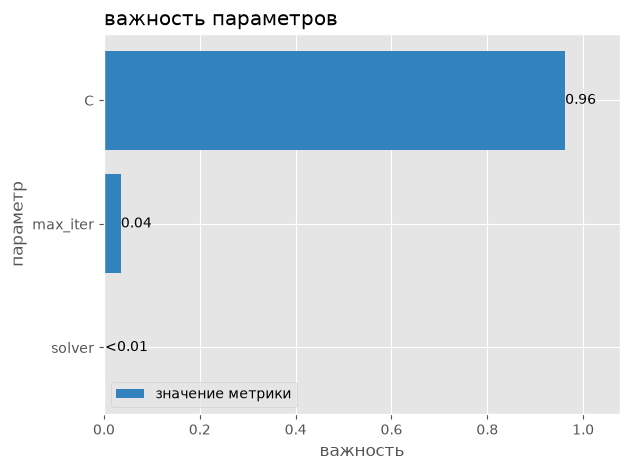

C           0.962424
max_iter    0.035332
solver      0.002245
Name: важность, dtype: float64

наиболее важный параметр: C


In [22]:
from optuna.visualization.matplotlib import plot_param_importances
ax = plot_param_importances(study)
ax.set_title('важность параметров', loc='left')
ax.set_xlabel('важность')
ax.set_ylabel('параметр')
legend = ax.get_legend()
if legend is not None:
    for label in legend.get_texts():
        label.set_text('значение метрики')
plt.tight_layout()
plt.show()
importance = optuna.importance.get_param_importances(study)
display(pd.Series(importance, name='важность'))
print('наиболее важный параметр:', max(importance, key=importance.get))

pd.Series(importance).to_json(OUTPUT / 'parameter_importance.json', force_ascii=False)
study.trials_dataframe().to_csv(OUTPUT / 'optuna_trials.csv', index=False)


## финальная модель

после выбора параметров модель обучается на всём очищенном train. модель, настройки и прогнозы сохраняются. test без ответов, поэтому его качество здесь неизвестно.

прогнозы, результаты сравнения, параметры и модель сохраняются в `artifacts/baseline/`.

после сохранения модель загружается и проверяется совпадение прогнозов.

In [23]:
import json
import cloudpickle
best_params = study.best_params
evaluate_model('optuna_best', make_hero_model(params=best_params), fit_clean, valid_clean)
display(pd.DataFrame(results))
final_model = make_hero_model(params=best_params)
final_model.fit(train_clean, train_clean['radiant_win'])
fallback_model = make_model(use_dates=use_dates, mmr=mmr_kind)
fallback_model.fit(train, train['radiant_win'])
predictions = fallback_model.predict_proba(test)[:, 1]
valid_composition = test['match_id'].isin(clean_ids)
predictions[valid_composition] = final_model.predict_proba(test.loc[valid_composition])[:, 1]
submission = pd.DataFrame({'ID': test['match_id'], 'Value': predictions})
assert len(submission) == len(test)
assert submission['ID'].equals(test['match_id'])
assert submission['Value'].between(0, 1).all()
submission.to_csv(OUTPUT / 'submission.csv', index=False)
pd.DataFrame(results).to_csv(OUTPUT / 'model_results.csv', index=False)
with open(OUTPUT / 'best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2)
with open(OUTPUT / 'dota_pipeline.pkl', 'wb') as f:
    cloudpickle.dump({'model': final_model, 'fallback': fallback_model, 'date_columns': date_columns, 'cutoff': cutoff, 'use_dates': use_dates, 'mmr_kind': mmr_kind}, f)
print('submission:', submission.shape)
display(submission.head())
with open(OUTPUT / 'dota_pipeline.pkl', 'rb') as f:
    restored = cloudpickle.load(f)
check_data = test.loc[valid_composition].head(20)
np.testing.assert_allclose(restored['model'].predict_proba(check_data), final_model.predict_proba(check_data))


,model,gini_train,gini_valid
0,dates,0.044577,0.004557
1,region,0.075595,0.075964
2,dates_region,0.096057,0.077887
3,mmr_raw,0.152860,0.145717
4,mmr_log,0.154762,0.146929
5,tabular_clean,0.154736,0.146817
6,heroes,0.277176,0.276154
7,all_features,0.313924,0.310960
8,optuna_best,0.313932,0.311008


submission: (59748, 2)


,ID,Value
0,8,0.420621
1,29,0.642317
2,34,0.628227
3,36,0.505042
4,61,0.593056


## что получилось

герои дали основной прирост базовой модели. даты и mmr добавили меньше. дальше проверяются чат и динамика преимущества. подбор на одном месяце может завысить оценку, поэтому для более надёжного вывода нужны дополнительные временные разбиения.